# Week 6 — Exploratory Data Analysis and Model Selection

**Producto:** InmoScore  
**Fecha de entrega:** 16 de septiembre de 2026  
**Unidad analítica:** anuncio inmobiliario publicado en Urbania  
**Objetivo:** validar estructura/calidad, explorar distribuciones y relaciones, y comparar una propuesta de modelado con dos líneas base.

Este notebook parte de los archivos procesados reproducibles. La fuente inicial y su trazabilidad desde `week04` se validan de forma explícita; el objetivo es **precio de oferta**, no precio de transacción.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

WEEK06 = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd() / "deliveries/week06"
ROOT = WEEK06.parents[1]
PROCESSED = WEEK06 / "data/processed"
RAW = WEEK06 / "data/raw"
FIGURES = WEEK06 / "figures"
FIGURES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "axes.titleweight": "bold"})

listings = pd.read_csv(PROCESSED / "listings_eda.csv")
raw_listings = pd.read_csv(RAW / "listings_urbania.csv")
model_comparison = pd.read_csv(PROCESSED / "model_comparison.csv")
print(f"Procesados: {len(listings):,} filas × {listings.shape[1]} columnas | Distritos: {listings.district.nunique()}")

Procesados: 3,896 filas × 30 columnas | Distritos: 20


## 1. Procedencia y trazabilidad desde Week 04

`week04` documenta la fuente inicial: un dataset público del repositorio `MathiuCz/lima-real-estate-price-predictor`, originalmente recopilado de Urbania. Week 06 usa los 3,987 registros completos, no solo las muestras versionadas de Week 04.

In [2]:
lineage = pd.read_csv(PROCESSED / "source_lineage_week04.csv")
display(lineage)
assert lineage.result.eq("PASS").all()

,check,numerator,denominator,result
0,week04_initial_listing_sample_ids_in_week06_raw,400,400,PASS
1,week04_analytical_sample_ids_in_week06_raw,500,500,PASS
2,week04_analytical_sample_ids_in_week06_feature...,500,500,PASS
3,shared_prices_identical,500,500,PASS
4,shared_areas_identical,500,500,PASS


## 2. Preprocesamiento y pérdida de filas

Se exige precio y área positivos. Después se calcula precio por m² y se aplica la regla IQR **dentro de cada distrito**, evitando que el nivel de precios de un distrito elimine observaciones válidas de otro. No se imputan variables estructuralmente ausentes del BCRP.

In [3]:
preprocessing = pd.read_csv(PROCESSED / "preprocessing_summary.csv")
display(preprocessing)
assert len(raw_listings) == 3987
assert len(listings) == 3896
print(f"Retención: {len(listings)/len(raw_listings):.2%}; removidos por IQR: {len(raw_listings)-len(listings):,}")

,stage,rows,rows_removed,rule
0,raw_urbania,3987,0,Acquired listing inventory
1,valid_price_area,3987,0,Require positive price and area
2,district_iqr_price_per_m2,3896,91,"Keep price/m2 within [Q1 - 1.5 IQR, Q3 + 1.5 I..."


Retención: 97.72%; removidos por IQR: 91


## 3. Validación de estructura y calidad

Se comprueban identificadores, duplicados, rangos, positividad, cobertura geográfica y ausencia. Los 62 registros señalados por dirección/precio/área son **candidatos**, no eliminaciones automáticas: pueden representar unidades distintas del mismo edificio.

In [4]:
quality = pd.DataFrame({
    "check": [
        "listing_id único", "precio positivo", "área positiva", "price_per_m2 finito",
        "índice criminal en [0,1]", "conveniencia en [0,1]", "índice zona en [0,1]",
    ],
    "violations": [
        listings.listing_id.duplicated().sum(),
        (~listings.price_soles.gt(0)).sum(),
        (~listings.area_m2.gt(0)).sum(),
        (~np.isfinite(listings.price_per_m2)).sum(),
        (~listings.crime_index_zone.between(0,1)).sum(),
        (~listings.urban_convenience_index.between(0,1)).sum(),
        (~listings.zone_composite_index.between(0,1)).sum(),
    ],
})
display(quality)
assert quality.violations.eq(0).all()

missing = listings.isna().mean().mul(100).sort_values(ascending=False)
display(missing[missing.gt(0)].rename("missing_pct").to_frame())
print(f"data_partial=True: {listings.data_partial.sum():,} ({listings.data_partial.mean():.2%})")

,check,violations
0,listing_id único,0
1,precio positivo,0
2,área positiva,0
3,price_per_m2 finito,0
4,"índice criminal en [0,1]",0
5,"conveniencia en [0,1]",0
6,"índice zona en [0,1]",0


,missing_pct
bcrp_price_rent_ratio,25.256674
bcrp_price_m2_usd,25.256674


data_partial=True: 984 (25.26%)


**Interpretación de la ausencia.** Ambos campos BCRP faltan en 25.26% de filas porque la serie oficial cubre 12 de los 20 distritos del inventario. `maintenance_fee=0` no se interpreta como gratuidad: puede significar “no informado”.

## 4. Distribuciones

Precio, área y precio por m² presentan cola derecha. Por ello se reportan medianas/cuartiles y se modela `log(price_soles)` con `log(area_m2)`.

,count,mean,std,min,1%,25%,50%,75%,99%,max
price_soles,3896.0,741812.81,727756.09,79000.00,159570.00,380000.00,539001.00,829625.00,4037685.00,10177500.00
area_m2,3896.0,119.27,89.44,21.00,36.00,67.00,90.00,137.00,515.25,827.00
price_per_m2,3896.0,6281.39,2232.53,1211.76,1937.14,4716.86,6236.33,7625.24,12252.08,15425.53
rooms,3896.0,2.66,0.89,1.00,1.00,2.00,3.00,3.00,5.00,10.00
bathrooms,3896.0,2.17,0.92,1.00,1.00,2.00,2.00,2.25,5.00,20.00
parking,3896.0,0.77,0.92,0.00,0.00,0.00,1.00,1.00,4.00,10.00


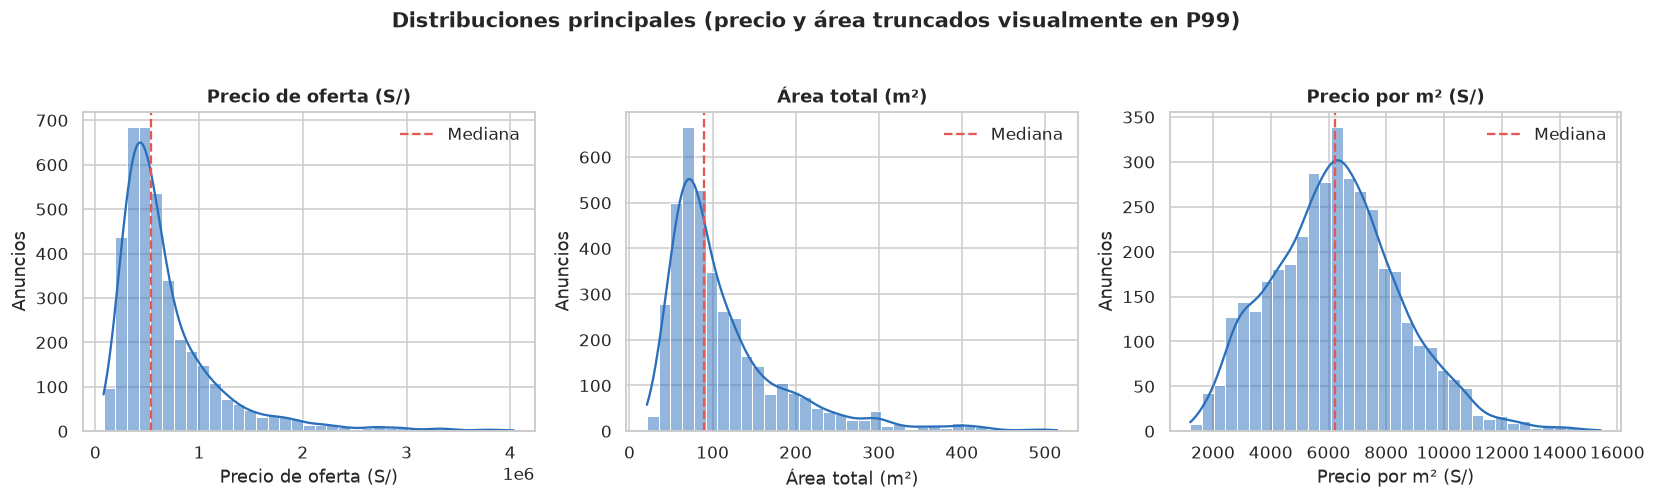

In [5]:
display(listings[["price_soles","area_m2","price_per_m2","rooms","bathrooms","parking"]]
        .describe(percentiles=[.01,.25,.5,.75,.99]).T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
specs = [
    ("price_soles", "Precio de oferta (S/)", 0.99),
    ("area_m2", "Área total (m²)", 0.99),
    ("price_per_m2", "Precio por m² (S/)", 1.00),
]
for ax, (column, label, upper_q) in zip(axes, specs):
    values = listings[column]
    if upper_q < 1:
        values = values[values <= values.quantile(upper_q)]
    sns.histplot(values, bins=35, kde=True, ax=ax, color="#2A6FBB")
    ax.axvline(values.median(), color="#E45756", ls="--", label="Mediana")
    ax.set(title=label, xlabel=label, ylabel="Anuncios")
    ax.legend(frameon=False)
fig.suptitle("Distribuciones principales (precio y área truncados visualmente en P99)", y=1.03, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "eda_distributions.png", bbox_inches="tight")
plt.show()

## 5. Cobertura distrital y heterogeneidad

La cobertura no es uniforme: Magdalena del Mar tiene 19 anuncios, mientras Jesús María tiene 289. Las comparaciones distritales deben acompañarse de `n`; los distritos pequeños tendrán mayor incertidumbre.

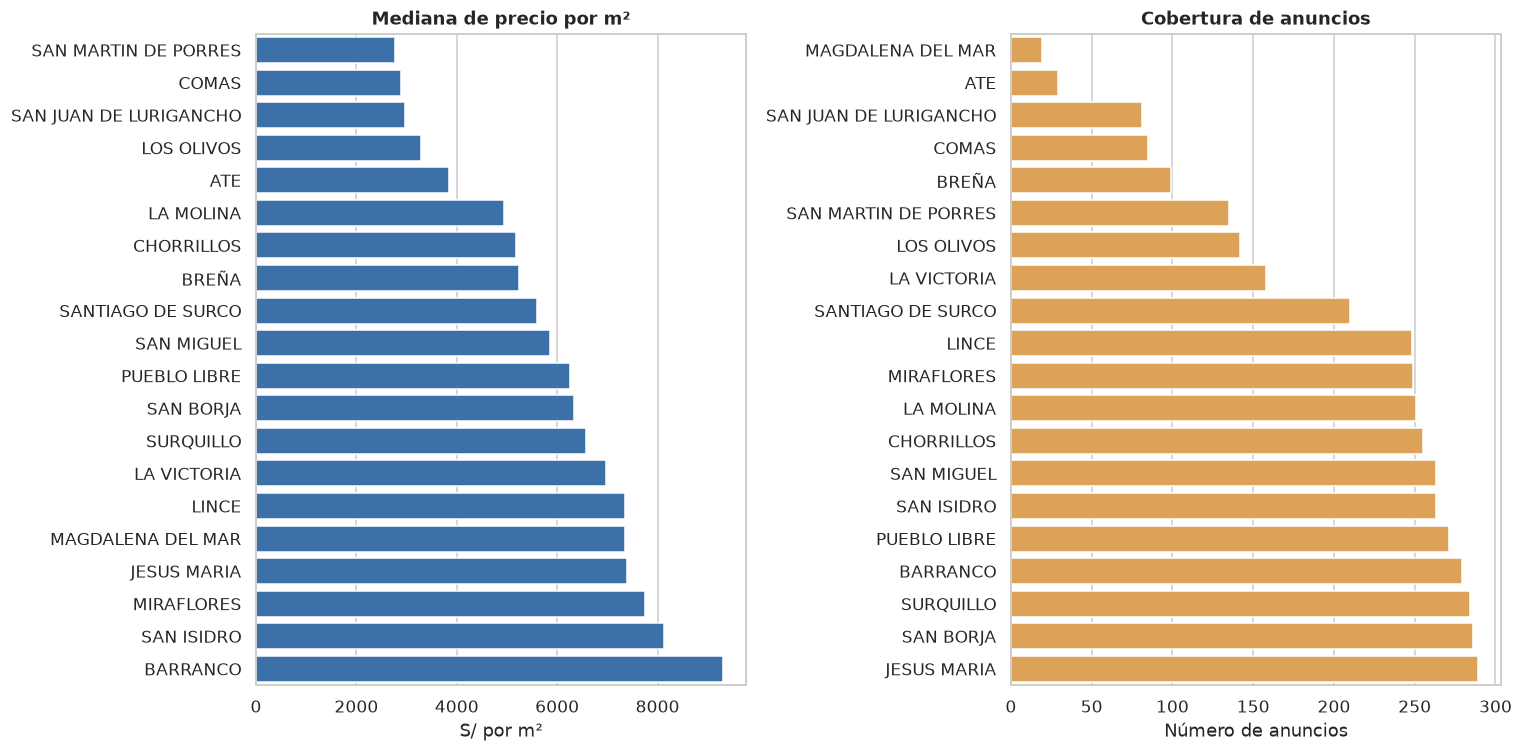

,district,n,median_price_m2
10,MAGDALENA DEL MAR,19,7358.490566
0,ATE,29,3837.719298
15,SAN JUAN DE LURIGANCHO,81,2964.843750
4,COMAS,85,2880.000000
2,BREÑA,99,5230.985915


In [6]:
district = (listings.groupby("district", as_index=False)
            .agg(n=("listing_id","size"), median_price_m2=("price_per_m2","median"))
            .sort_values("median_price_m2"))
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
sns.barplot(data=district, y="district", x="median_price_m2", ax=axes[0], color="#2A6FBB")
axes[0].set(title="Mediana de precio por m²", xlabel="S/ por m²", ylabel="")
sns.barplot(data=district.sort_values("n"), y="district", x="n", ax=axes[1], color="#F2A541")
axes[1].set(title="Cobertura de anuncios", xlabel="Número de anuncios", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "eda_districts.png", bbox_inches="tight")
plt.show()
display(district.sort_values("n").head(5))

## 6. Relaciones y riesgo de fuga

`price_per_m2`, `baseline_price_soles` y `opportunity_score_baseline` derivan directa o indirectamente del objetivo; se usan para diagnóstico, pero se excluyen del candidato predictivo. Las variables distritales se repiten entre anuncios y no equivalen a mediciones a nivel de inmueble.

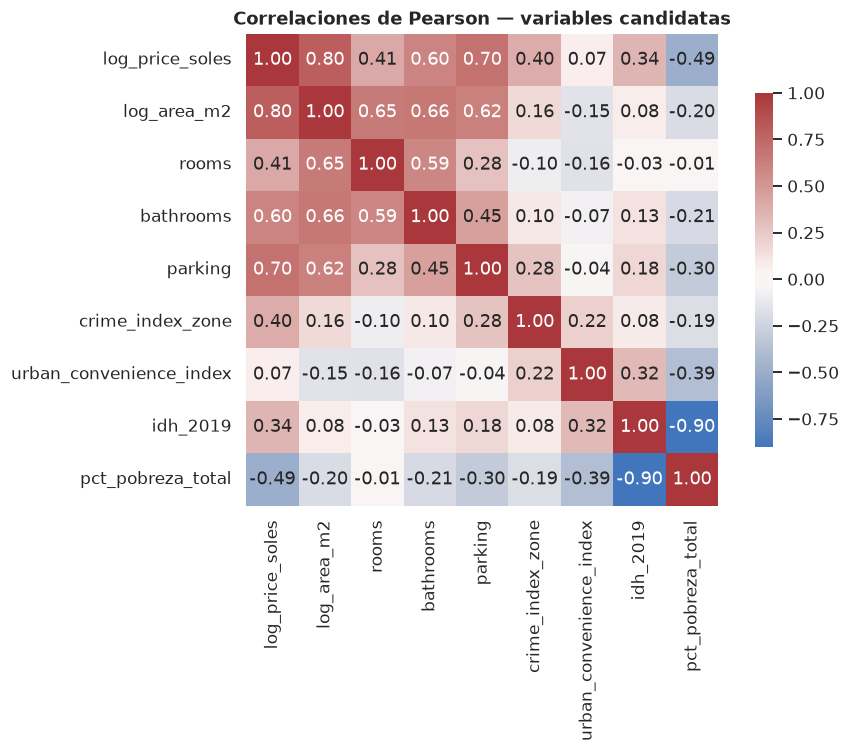

In [7]:
corr_cols = ["log_price_soles","log_area_m2","rooms","bathrooms","parking",
             "crime_index_zone","urban_convenience_index","idh_2019","pct_pobreza_total"]
corr = listings[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax, square=True,
            cbar_kws={"shrink": .75})
ax.set_title("Correlaciones de Pearson — variables candidatas")
fig.tight_layout()
fig.savefig(FIGURES / "eda_correlations.png", bbox_inches="tight")
plt.show()

## 7. Selección preliminar del modelo

La partición 80/20 es estable y basada en un hash de distrito+dirección; anuncios con la misma dirección no cruzan entre entrenamiento y prueba. Se comparan:

1. mediana distrital de precio por m² × área;
2. regresión log-lineal con área y distrito;
3. Ridge sobre log-precio con atributos del inmueble y contexto distrital.

,model,n_train,n_test,mae_soles,rmse_soles,mae_soles_per_m2,mdape,p90_ape,r2_log_price
0,ridge_contextual_log_price,3116,780,"S/ 141,372","S/ 270,269","S/ 1,055",13.58%,37.28%,0.886
1,log_linear_area_district,3116,780,"S/ 152,591","S/ 296,501","S/ 1,120",14.72%,37.78%,0.871
2,district_median_price_m2,3116,780,"S/ 157,482","S/ 280,359","S/ 1,197",15.38%,39.44%,0.850


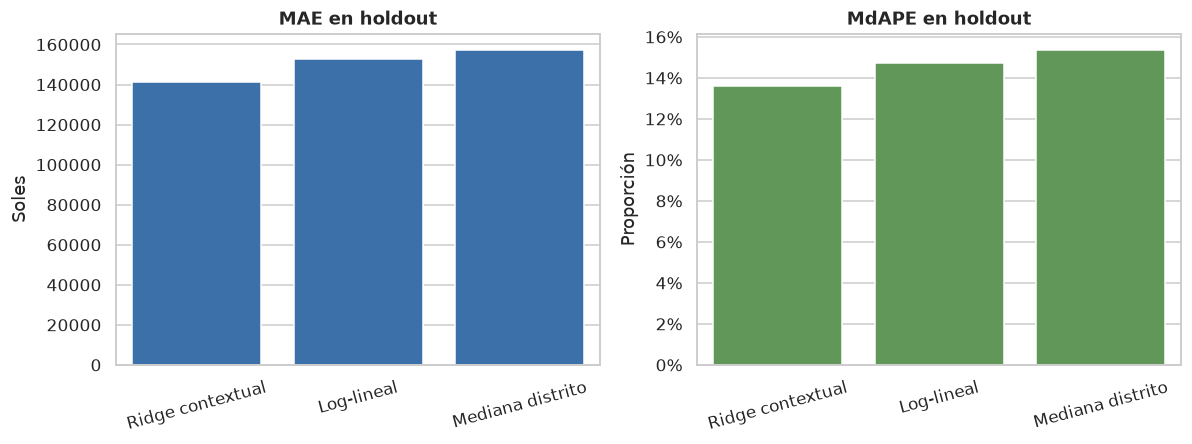

In [8]:
metrics_display = model_comparison.copy()
for column in ["mae_soles", "rmse_soles", "mae_soles_per_m2"]:
    metrics_display[column] = metrics_display[column].round(0).map(lambda value: f"S/ {value:,.0f}")
for column in ["mdape", "p90_ape"]:
    metrics_display[column] = metrics_display[column].map(lambda value: f"{value:.2%}")
metrics_display["r2_log_price"] = metrics_display["r2_log_price"].round(3)
display(metrics_display)

plot_metrics = model_comparison.copy()
plot_metrics["model_label"] = plot_metrics.model.map({
    "district_median_price_m2": "Mediana distrito",
    "log_linear_area_district": "Log-lineal",
    "ridge_contextual_log_price": "Ridge contextual",
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.barplot(data=plot_metrics, x="model_label", y="mae_soles", ax=axes[0], color="#2A6FBB")
axes[0].set(title="MAE en holdout", xlabel="", ylabel="Soles")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=plot_metrics, x="model_label", y="mdape", ax=axes[1], color="#59A14F")
axes[1].set(title="MdAPE en holdout", xlabel="", ylabel="Proporción")
axes[1].tick_params(axis="x", rotation=15)
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(FIGURES / "model_comparison.png", bbox_inches="tight")
plt.show()

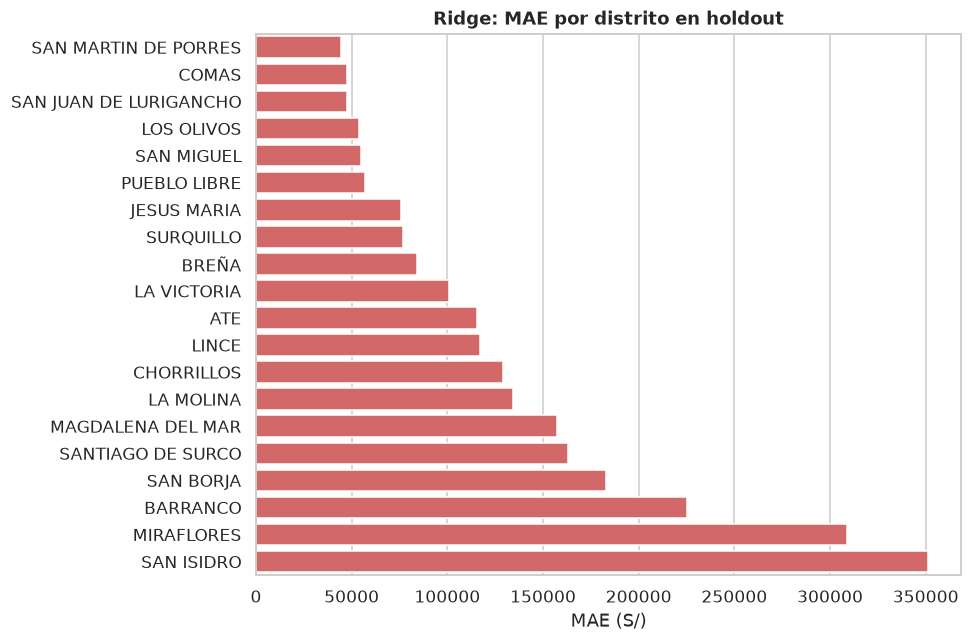

,model,district,n_test,mae_soles,mdape,bias_soles
58,ridge_contextual_log_price,SANTIAGO DE SURCO,43,163003.9905,0.1331,37983.6952
53,ridge_contextual_log_price,SAN BORJA,70,182827.9476,0.1424,-58128.3407
41,ridge_contextual_log_price,BARRANCO,58,225046.3177,0.1148,-63513.2366
51,ridge_contextual_log_price,MIRAFLORES,47,308701.0893,0.2034,-138331.3274
54,ridge_contextual_log_price,SAN ISIDRO,57,351093.6539,0.1594,44824.6407


In [9]:
residuals = pd.read_csv(PROCESSED / "model_residuals_by_district.csv")
ridge_residuals = residuals[residuals.model.eq("ridge_contextual_log_price")].sort_values("mae_soles")
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=ridge_residuals, y="district", x="mae_soles", color="#E45756", ax=ax)
ax.set(title="Ridge: MAE por distrito en holdout", xlabel="MAE (S/)", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "model_residuals_district.png", bbox_inches="tight")
plt.show()
display(ridge_residuals.tail(5))

## 8. Hallazgos, sesgos y decisión

- Ridge reduce el MAE preliminar respecto de la mediana distrital y también mejora el error relativo; es el candidato seleccionado para la siguiente iteración.
- El resultado **no demuestra** valor de mercado: la etiqueta es precio publicado y no una transacción cerrada.
- La muestra proviene de un portal, cubre 20 distritos y no es aleatoria; el desempeño no se generaliza automáticamente a todo Lima.
- SIDPOL mide denuncias reportadas, OSM depende de intensidad de mapeo y MIVIVIENDA no representa toda la obra nueva.
- No hay fecha fiable por anuncio, coordenadas completas, antigüedad, piso, estado ni imágenes etiquetadas; estas ausencias limitan validación temporal y precisión por inmueble.
- Próxima evaluación: validación temporal cuando exista fecha, intervalos de incertidumbre y auditoría de error por distrito/rango de precio. Mantener la línea base distrital como guardrail.